In [2]:
import pandas as pandamanicobar
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,MinMaxScaler



In [3]:
df = pandamanicobar.read_csv('./titanic.csv')
print(df.head(2))

   PassengerId  Survived  Pclass  ...     Fare Cabin  Embarked
0            1         0       3  ...   7.2500   NaN         S
1            2         1       1  ...  71.2833   C85         C

[2 rows x 12 columns]


In [4]:

print(df.info())
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [5]:

male_df = df[df['Sex'] == "male"]
female_df = df[df['Sex'] == "female"]

# sns.lineplot(y='Survived',x='Age',data=female_df)
# plt.title("Female: Survival vs Age")
# plt.show()
# sns.lineplot(y='Survived',x='Age',data=male_df)
# plt.title("Male: Survival vs Age")
# plt.show()

In [6]:
features = ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
features = ['Survived', 'Pclass','Sex', 'Age', 'SibSp',
       'Parch','Fare', 'Cabin', 'Embarked']

categorical = ['Pclass','Sex','Embarked']
# for feat in features:    
#     sns.barplot(y='Survived',x=feat,data=df)
#     plt.title(f"{feat} vs Survived")
#     plt.show()

In [7]:
# identify column datatypes 
# make the list of categorical and numerical columns

cat_col = [col for col in df.columns if df[col].dtype == 'object']
num_col = [col for col in df.columns if df[col].dtype != 'object']

print(cat_col,num_col)


['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'] ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


In [8]:
# count unique value in the categorical columns 
# .nunique()

print(df[cat_col].nunique(0))
print(df[num_col].nunique(0))

Name        891
Sex           2
Ticket      681
Cabin       147
Embarked      3
dtype: int64
PassengerId    891
Survived         2
Pclass           3
Age             88
SibSp            7
Parch            7
Fare           248
dtype: int64


In [9]:
# calculate the missing values in the dataset
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
df.shape[0]

891

In [11]:
# missing value percentages

round((df.isnull().sum()/(df.shape[0]))*100,2)

PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

In [12]:
# drop irrelevant columns or heavy missing columns
# df.drop() # delele specific columns
# dropna() # delele rows with missing values
# fillna() # filling missing values with specific

In [13]:
df1 = df.drop(columns=['Cabin','Ticket'],axis=1)
df1.dropna(subset=['Embarked'],inplace=True)
round((df1.isnull().sum()/(df1.shape[0]))*100,2)


PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.91
SibSp           0.00
Parch           0.00
Fare            0.00
Embarked        0.00
dtype: float64

In [14]:
df1['Age'] = df1['Age'].fillna(df1['Age'].mean())
round((df1.isnull().sum()/(df1.shape[0]))*100,2)


PassengerId    0.0
Survived       0.0
Pclass         0.0
Name           0.0
Sex            0.0
Age            0.0
SibSp          0.0
Parch          0.0
Fare           0.0
Embarked       0.0
dtype: float64

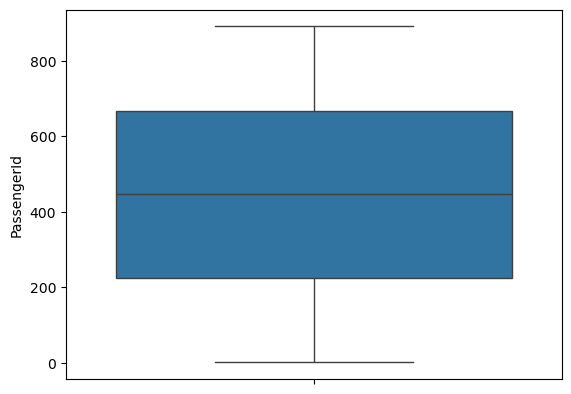

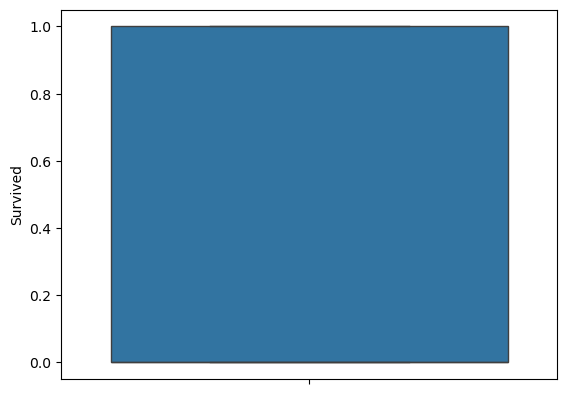

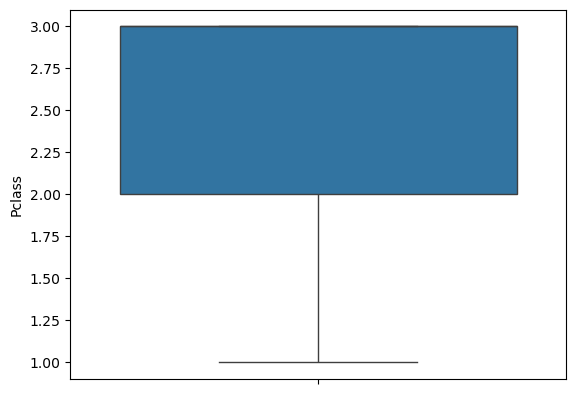

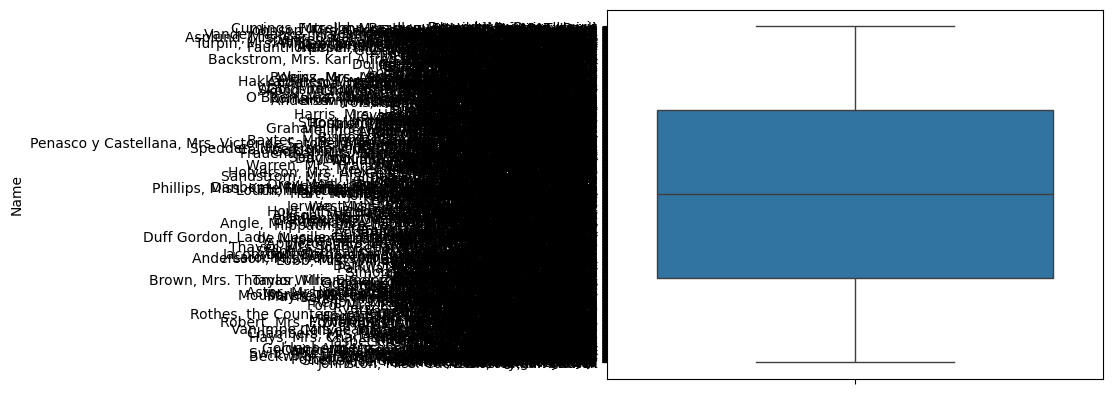

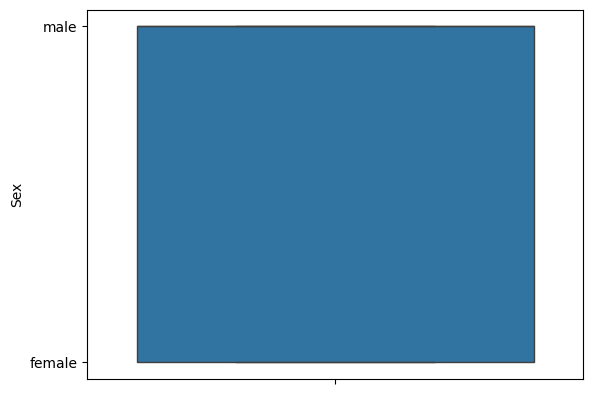

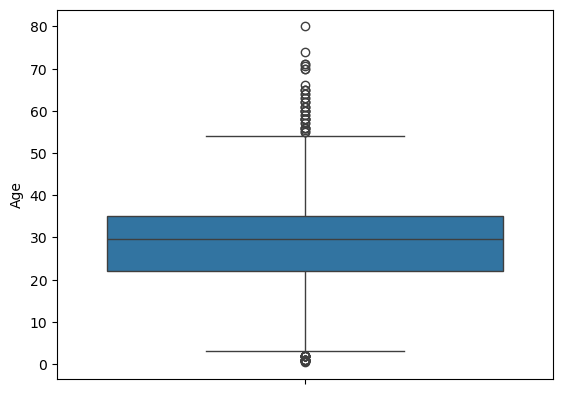

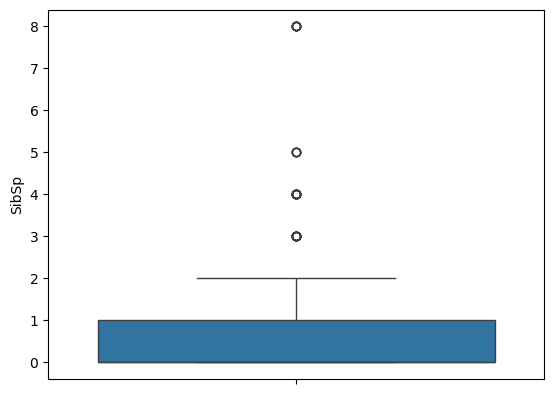

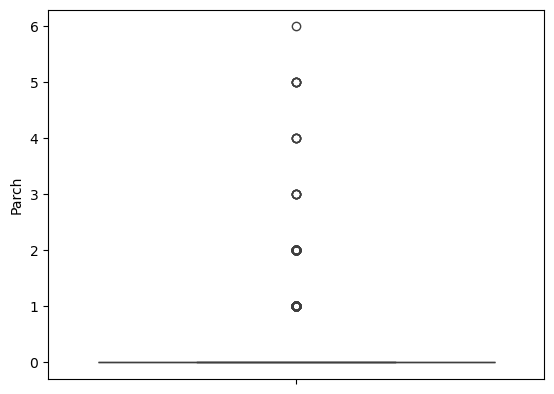

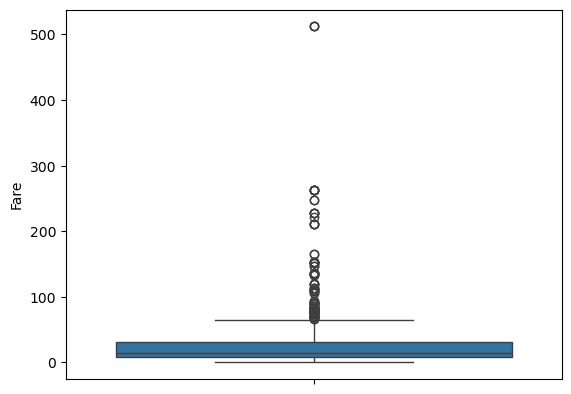

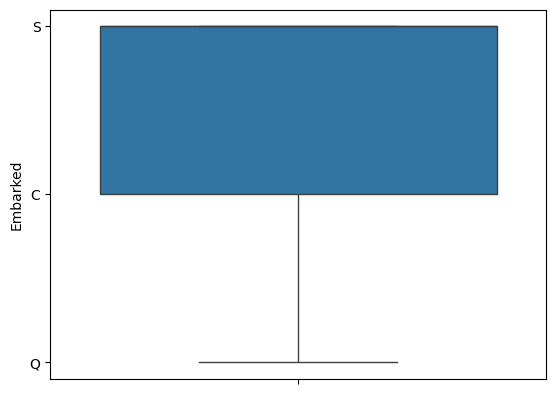

In [15]:
# Detect outliers with boxplot
for feat in df1.columns:
    sns.boxplot(y=feat,data=df1)
    plt.show()
    


In [16]:
# calculate outliers boundaries and remove them
mean = df1['Age'].mean()
std = df1['Age'].std()

lb = mean-2*std
ub = mean+2*std



df3 = df1[(df1['Age']>lb) & (df1['Age']<ub)]

mean = df3['Age'].mean()
std = df3['Age'].std()

lb = mean-2*std
ub = mean+2*std
df4 = df3[(df3['Age']>lb) & (df3['Age']<ub)]


# sns.boxplot(x='Age',data=df1,)
# plt.show()
# sns.boxplot(x='Age',data=df3)
# plt.show()
# sns.boxplot(x='Age',data=df4,)
# plt.show()




In [17]:
print(df1.shape[0])
print(df3.shape[0])
print(df4.shape[0])
print(df4.columns)


889
821
762
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Fare', 'Embarked'],
      dtype='object')


In [18]:
df4.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S


In [62]:
# Separate the dependent and independent columns
X = df4[['Pclass','Sex','Age','SibSp','Parch', 'Fare', 'Embarked']]
Y = df4['Survived']

print(X.head(1))
print(type(X))
print(Y.head(1))

   Pclass   Sex   Age  SibSp  Parch  Fare Embarked
0       3  male  22.0      1      0  7.25        S
<class 'pandas.core.frame.DataFrame'>
0    0
Name: Survived, dtype: int64


In [63]:
# we need to convert Age and Embarked to integer 

from sklearn.preprocessing import LabelEncoder
labelEncoder = LabelEncoder()
X["Sex"] = labelEncoder.fit_transform(X['Sex'])
X["Embarked"] = labelEncoder.fit_transform(X['Embarked'])
print(X)


     Pclass  Sex        Age  SibSp  Parch     Fare  Embarked
0         3    1  22.000000      1      0   7.2500         2
1         1    0  38.000000      1      0  71.2833         0
2         3    0  26.000000      0      0   7.9250         2
3         1    0  35.000000      1      0  53.1000         2
4         3    1  35.000000      0      0   8.0500         2
..      ...  ...        ...    ...    ...      ...       ...
886       2    1  27.000000      0      0  13.0000         2
887       1    0  19.000000      0      0  30.0000         2
888       3    0  29.642093      1      2  23.4500         2
889       1    1  26.000000      0      0  30.0000         0
890       3    1  32.000000      0      0   7.7500         1

[762 rows x 7 columns]


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_12968\3671600854.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Sex"] = labelEncoder.fit_transform(X['Sex'])
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_12968\3671600854.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Embarked"] = labelEncoder.fit_transform(X['Embarked'])


In [64]:
# Scaling the data so our algorithm can understand fast and predict fast

scaler = MinMaxScaler(feature_range=(0,1))

num_col = [col for col in X.columns if X[col].dtype != 'object']
X1 = X

X1[num_col] = scaler.fit_transform(X1[num_col])

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_12968\11168591.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X1[num_col] = scaler.fit_transform(X1[num_col])


In [72]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train ,y_test = train_test_split(X1,Y,test_size=0.2,random_state=69)

In [77]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
print(X1.head(1))
model.fit(x_train,y_train)

   Pclass  Sex    Age  SibSp  Parch      Fare  Embarked
0     1.0  1.0  0.325  0.125    0.0  0.014151       1.0


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [81]:
print(x_train.shape)
print(x_test.shape)

(609, 7)
(153, 7)


In [86]:
# model evaluation

from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix

acc_score = accuracy_score(y_test,model.predict(x_test))
print(acc_score)

0.8169934640522876


In [82]:
Y_pred = pandamanicobar.DataFrame({
    'Survived': model.predict(x_test)
})

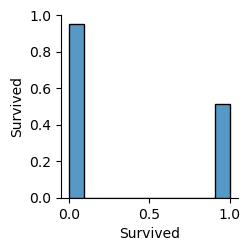

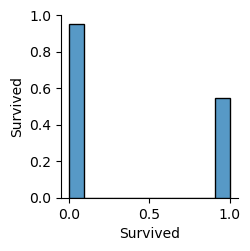

In [79]:
sns.pairplot(data=Y_pred)
plt.show()
sns.pairplot(data=pandamanicobar.DataFrame({"Survived": df4["Survived"]}))
plt.show()

In [ ]:
plt.pie(
    df4["Survived"].value_counts(),
    labels=['Survived','died'],
    autopct="%.f%%",
    shadow=True
)
plt.title("Survived distribution")
plt.show()

plt.pie(
    Y_pred["Survived"].value_counts(),
    labels=['Survived','died'],
    autopct="%.f%%",
    shadow=True
)
plt.title("Survived Predicted distribution")
plt.show()

KeyError: 'Survived'